In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
def plot_combined_roc(model_configs, target_class=None, save_path='tb11k_combined_roc.png'):
    
    plt.figure(figsize=(9, 8))
    sns.set_theme(style="whitegrid", font_scale=1.2)
    
    print(f"{'='*20} Plotting Combined ROC for TB11K {'='*20}")
    
    # 遍历所有模型配置
    for model_name, config in model_configs.items():
        file_path = config['path']
        
        if not os.path.exists(file_path):
            print(f"[Error] File not found: {file_path}")
            continue
            
        # --- 关键步骤：读取 npy 字典 ---
        # 注意：必须使用 .item() 才能把 numpy object 转回 python dict
        try:
            data_dict = np.load(file_path, allow_pickle=True).item()
        except Exception as e:
            print(f"[Error] Failed to load {file_path}: {e}")
            continue
        
        # 自动确定类别名称 (如果未指定)
        if target_class is None:
            # 获取字典里的第一个 key (通常就是 'TB')
            target_class = list(data_dict.keys())[0]
            
        if target_class not in data_dict:
            print(f"[Warning] Class '{target_class}' not found in {model_name}")
            continue
            
        # 提取数据
        class_data = data_dict[target_class]
        fpr = class_data['fpr']
        tpr = class_data['tpr']
        auc_val = class_data['auc']
        
        # 绘图
        plt.plot(
            fpr, tpr, 
            label=f'{model_name} (AUC = {auc_val:.4f})',
            color=config['color'],
            linestyle=config['style'],
            linewidth=config['linewidth'],
            alpha=0.9
        )
        print(f"Loaded {model_name}: AUC={auc_val:.4f}")

    # --- 美化图表 ---
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle=':', alpha=0.6, label='Random Guess')
    
    plt.xlim([-0.02, 1.0])
    plt.ylim([0.0, 1.02])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=14, fontweight='bold')
    plt.ylabel('True Positive Rate (Sensitivity)', fontsize=14, fontweight='bold')
    plt.title(f'Ablation Study ROC Curves ({target_class})', fontsize=16, fontweight='bold', pad=15)
    
    # 图例设置
    plt.legend(loc="lower right", fontsize=12, frameon=True, fancybox=True, framealpha=0.9, borderpad=1)
    
    # 网格
    plt.grid(False)
    
    # 保存
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nFigure saved to: {save_path}")
    
    plt.show()

==================== Plotting Combined ROC for TB11K ====================
Loaded Baseline: AUC=0.9960
Loaded WID: AUC=0.9993
Loaded EDL: AUC=0.9970
Loaded WID+EDL: AUC=0.9996

Figure saved to: ./figures/TB11K/ab_rocs_merge_TB11K_val.png


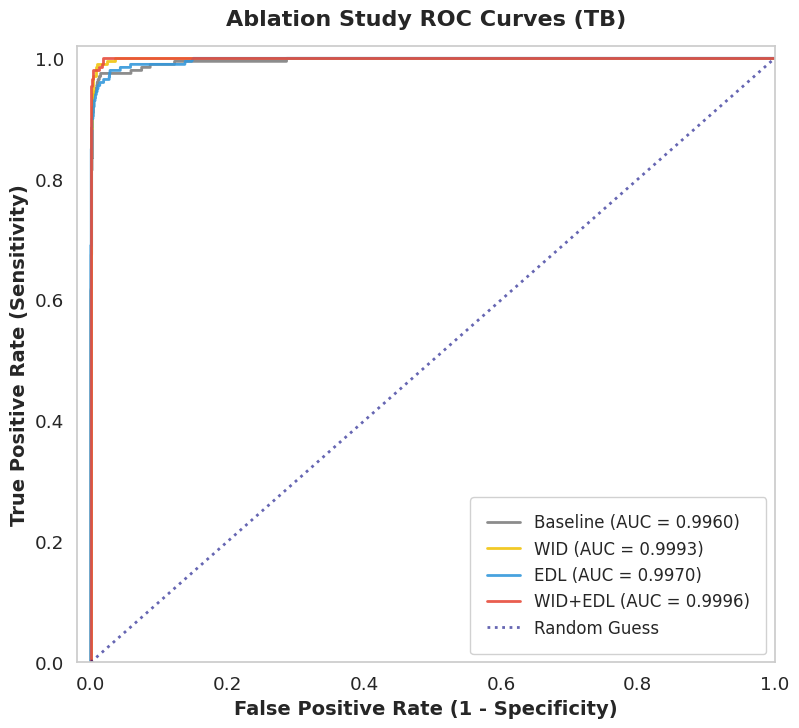

In [3]:
# ==============================================================================
# 2. 配置：定义模型名称和对应的 .npy 文件路径
# ==============================================================================
# 建议：按照 "Baseline -> 中间态 -> 最终模型" 的顺序排列，图例更清晰
dataset_name = 'MIMIC'
subset_name = 'val'
class_name = 'Cardiomegaly'
model_configs = {
    'Baseline': {
        'path': f'../result/{dataset_name}/0203_{class_name}_wd0_0001_gc1_0_vw1_0_lm_bce_lr_0.0005_kllmd_0.1_imgdec_0/{subset_name}_evaluation_results/roc_curve_data.npy', # 请修改为真实路径
        'color': 'gray',
        'style': '-',
        'linewidth': 2
    },
    'WID': {
        'path': f'../result/{dataset_name}0203_{class_name}_wd0_0001_gc1_0_vw1_0_lm_bce_lr_0.0005_kllmd_0.1_imgdec_0/{subset_name}_evaluation_results/roc_curve_data.npy',   # 请修改为真实路径
        'color': '#f1c40f',  # 黄色
        'style': '-',
        'linewidth': 2
    },
    'EDL': {
        'path': f'../result/{dataset_name}/0203_{class_name}_wd0_0001_gc1_0_vw1_0_lm_bce_lr_0.0005_kllmd_0.1_imgdec_0/{subset_name}_evaluation_results/roc_curve_data.npy',      # 请修改为真实路径
        'color': '#3498db',  # 蓝色
        'style': '-',
        'linewidth': 2
    },
    'WID+EDL': {
        'path': f'../result/{dataset_name}/0203_{class_name}_wd0_0001_gc1_0_vw1_0_lm_bce_lr_0.0005_kllmd_0.1_imgdec_0/{subset_name}_evaluation_results/roc_curve_data.npy', # 请修改为真实路径
        'color': '#e74c3c',  # 红色 (最显眼)
        'style': '-',        # 实线
        'linewidth': 2       # 更粗
    }
}

# 指定你要画的类别名称 (TB11K通常只有一个正类，比如 'TB')
# 如果你不确定 key 是什么，代码会自动获取第一个 key
TARGET_CLASS = 'TB' 
# ==============================================================================
# 3. 执行
# ==============================================================================

plot_combined_roc(model_configs, target_class=TARGET_CLASS, save_path=f'./figures/TB11K/ab_rocs_merge_{dataset_name}_{subset_name}.png')